In [100]:
from openai import OpenAI
import os
import json
import re

In [60]:
! uv pip install openai

Using Python 3.12.3 environment at: /home/ADWKS.UHB.FR/mallart_c/Documents/hackaton_llm_temporal_reasoning/.venv
Resolved 14 packages in 836ms                                        
Prepared 6 packages in 725ms                                                 openai               ------------------------------ 1.86 MiB/1.97 MiB           openai               ------------------------------ 255.36 KiB/1.97 MiB         openai               ------------------------------ 32.00 KiB/1.97 MiB          openai               ------------------------------ 16.00 KiB/1.97 MiB          
Installed 6 packages in 110ms                               
 + httpcore2==2.13.1
 + httpx2==2.13.1
 + jiter==0.17.0
 + openai==3.19.0
 + sniffio==1.3.1
 + truststore==0.10.4


In [258]:
API_KEY = "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"
MODEL = "~deepseek/deepseek-flash-latest"
CORPUS_FILE_PATH = "./annotations_remarks/annotated_corpus"
OUTPUT_PATH = "./outputs/"
ANNOTATIONS_PATH = "./annotations_remarks/annotations"

os.makedirs(OUTPUT_PATH, exist_ok=True)

In [259]:
client = OpenAI(base_url="https://openrouter.ai/api/v1",api_key=API_KEY)

## 1. Extracting events

### Prompting LLM

In [308]:
SYSTEM_PROMPT = """
CONTEXT: You are an annotator. Your job is to extract and annotate events in texts. 

ADDITIONAL CONTEXT:
The texts that you work on are in Modern Chinese, Ancient Chinese and English.
You extract only the events that have a temporal marker : a date, an expression (such as "last week", "after the meeting", "in the spring")
You pay attention to non-standard time expressions in classic Chinese (such as 鸡鸣, 东风解冻 or 一炷香).
Time may be given in either ISO format (YYYY-mm-dd) or in dynasty, era, reign, sexagenary, month and/or season, double hour format. 
Dates are not to be converted, slots are filled in the original format expressed in the text. 


MANDATORY RESPONSE FORMAT: A JSON structured text. 
Expected JSON structure:
{"events":
    [
        {"event_id": "str, prefix+integer",
        "event": "str, the plain text containing the event mention",
        "source_file" : "str, path of the file where the event appears",
        "event_location" : "tuple(int, int), (index of character where the text starts in the file, index of character where it ends)",
        "time_related_expressions": "list[tuple(str, int, int)], a list of (expression, character_start, character_end), the expressions that determine the timing of the event, not relative to any other event"],
        "event_type": "str, one of <punctual, recurring, range> ",
        "event_time_start": "time_stamp (including XX if information is unknown) OR string indicating a reference period such as summer, winter, in his old days, at the end of the century OR Null",
        "event_time_end": "time_stamp (including XX if information is unknown) OR string indicating a reference period such as summer, winter, in his old days, at the end of the century OR Null",
        "duration": "(min(unit,value), max(unit,value)) or Null",
        "utterance_time" : "time_stamp at which the document was written (to be found in metadata)"
    }
]
} 

INSTRUCTIONS :
- DO NOT INVENT time if not explicitely given in the text
- **DO NOT INFER** time information to fill all slots
- DO NOT CONVERT into ISO format if date is not given in ISO format.
- CREATE "event_id", a unique identifier for each event, using the filename
- DO NOT CREATE ANY OTHER INFORMATION than event_id
"""


#We should provide a calendar conversion

In [309]:
corpus = []
for filename in os.listdir(CORPUS_FILE_PATH):
    filepath = os.path.join(CORPUS_FILE_PATH, filename)
    if os.path.isfile(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            corpus.append((filename, f.read()))

In [310]:
if not corpus:
    raise ValueError("Aucun fichier trouvé dans CORPUS_FILE_PATH — vérifiez le chemin.")

In [311]:
corpus_text = "\n\n".join(
    f"### FILE: {filename}\n{content}" for filename, content in corpus
)

In [312]:
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user","content": corpus_text}
]

In [313]:
try:
    response = client.chat.completions.create(
        model=MODEL,
        messages=messages, #[{'role':'user', 'content':"say hi"}],
        temperature=0.3,
        extra_body={"reasoning": {"effort": "none"}}
    )
    #print(response.choices[0].message.content)
except Exception as e:
    print(f"Erreur lors de l'appel à l'API : {e}")

In [318]:
raw = response.choices[0].message.content

In [319]:
cleaned = re.sub(r"^```json|```$", "", raw.strip(), flags=re.MULTILINE).strip()

In [320]:
data = json.loads(cleaned)

In [321]:
data

{'events': [{'event_id': 'KR4d0466-WYG-f011-0010_建昌路重建太平橋記_1',
   'event': '壬辰六月郡侯章公總管趙公帥同僚洎郡寓公大家度材鳩工',
   'source_file': 'KR4d0466-WYG-f011-0010_建昌路重建太平橋記.txt',
   'event_location': [79, 120],
   'time_related_expressions': [['壬辰六月', 79, 83]],
   'event_type': 'punctual',
   'event_time_start': '壬辰六月',
   'event_time_end': '壬辰六月',
   'duration': None,
   'utterance_time': None},
  {'event_id': 'KR4d0466-WYG-f011-0010_建昌路重建太平橋記_2',
   'event': '癸已十一月始事',
   'source_file': 'KR4d0466-WYG-f011-0010_建昌路重建太平橋記.txt',
   'event_location': [120, 128],
   'time_related_expressions': [['癸已十一月', 120, 125]],
   'event_type': 'punctual',
   'event_time_start': '癸已十一月',
   'event_time_end': '癸已十一月',
   'duration': None,
   'utterance_time': None},
  {'event_id': 'KR4d0466-WYG-f011-0010_建昌路重建太平橋記_3',
   'event': '越明年七月落成',
   'source_file': 'KR4d0466-WYG-f011-0010_建昌路重建太平橋記.txt',
   'event_location': [128, 135],
   'time_related_expressions': [['越明年七月', 128, 133]],
   'event_type': 'punctual',
   'ev

In [322]:
output_file = os.path.join(OUTPUT_PATH, "results_events_extractions_deepseek_flash_old_schema_no_event_def.json")
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=2)

### Evaluation of extractions

In [323]:
from collections import Counter 

In [324]:
annotations = []
for filename in os.listdir(ANNOTATIONS_PATH):
    filepath = os.path.join(ANNOTATIONS_PATH, filename)
    if os.path.isfile(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            print(filepath)
            annotation_raw =f.read()
            annot = json.loads(annotation_raw)
            annotations.append(annot)

./annotations_remarks/annotations/annotations_enc_rotary_en_1319854677.json
./annotations_remarks/annotations/INSCR-KR4d0232-WYG-f006-0002.json
./annotations_remarks/annotations/annotations_enc_rotary_cmn_SPSP193109022001.json
./annotations_remarks/annotations/structure_example_TW_po_zh_8342_ZC.json
./annotations_remarks/annotations/annotations_enc_rotary_en_1319843498.json
./annotations_remarks/annotations/annotations_enc_exp_cmn_SPSP192606271118.json
./annotations_remarks/annotations/annotations_enc_exp_cmn_SPSP192708311019.json
./annotations_remarks/annotations/structure_example_LD.json
./annotations_remarks/annotations/annotations_enc_rotary_cmn_SPSP192506121501.json
./annotations_remarks/annotations/INSCR-KR4d0466-WYG-f011-0010.json


In [325]:
total_annot_per_corpus = []
for annot in annotations :
    name_corpus = list(annot.keys())[0]
    event_ids = [annot[name_corpus]["events"][i]["event_id"] for i in range(len(annot[name_corpus]["events"]))]
    total_annot_per_corpus.extend(event_ids)

In [326]:
total_annot_per_corpus = ["_".join(idx.split("_")[:-1]) for idx in total_annot_per_corpus]

In [330]:
corpus_events_extracted = []
for i in range(len(data["events"])):
    event_id = data["events"][i]["event_id"]
    corpus_events_extracted.append("_".join(event_id.split("_")[:-1]))

In [331]:
Counter(corpus_events_extracted)

Counter({'1319854677': 11,
         '1319843498': 10,
         'po_zh_8342': 5,
         'SPSP192708311019': 5,
         'KR4d0466-WYG-f011-0010_建昌路重建太平橋記': 3,
         'KR4d0232-WYG-f006-0002_撫州新作浮橋記': 3,
         'SPSP192606271118': 2,
         'po_en_1669': 1,
         'SPSP192506121501': 1,
         'SPSP193109022001': 1})

In [253]:
Counter(total_annot_per_corpus)
#Note : chenshuibian and all the names in chinese are from the same annotation set (on TW)

Counter({'id_enc_rotary_en_1319843498': 15,
         'id_SPSP192708311019': 10,
         'KR4d0232-WYG-f006-0002': 8,
         'KR4d0466-WYG-f011-0010': 7,
         'id_SPSP192606271118': 6,
         'TW': 4,
         'id_enc_rotary_en_1319854677': 3,
         'id_SPSP193109022001': 2,
         'chenshuibian': 2,
         'id_SPSP192506121501': 2,
         '「中二高」南投路段': 1,
         '「國道六號南投段」的開闢': 1,
         '「國道六號南投段」的興建': 1,
         '民眾對休閒旅遊的需求': 1,
         '政府': 1,
         '興建': 1})

In [254]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [299]:
#With prompt version 3 (new schema)
columns = ["file", "extracted", "annotated"]
lines = [
    ['1319854677', 11, 3],
    ['1319843498', 10, 15],
    ['SPSP192708311019', 5, 10],
    ['KR4d0466-WYG-f011-0010', 4, 7],
    ['KR4d0232-WYG-f006-0002', 4, 8],
    ['po_zh_8342', 4, 8],
    ['SPSP192606271118', 2, 6],
    ['po_en_1669', 1, 4],
    ['SPSP192506121501', 1, 2],
    ['SPSP193109022001', 1, 2]
]
matrix_conf1 = pd.DataFrame(lines, columns = columns)


In [300]:
#with old schema  + event def
columns = ["file", "extracted", "annotated"]
lines = [
    ['1319854677', 9, 3],
    ['1319843498', 9, 15],
    ['SPSP192708311019', 5, 10],
    ['KR4d0466-WYG-f011-0010', 5, 7],
    ['KR4d0232-WYG-f006-0002', 3, 8],
    ['po_zh_8342', 5, 8],
    ['SPSP192606271118', 2, 6],
    ['po_en_1669', 1, 4],
    ['SPSP192506121501', 1, 2],
    ['SPSP193109022001', 1, 2]
]
matrix_conf2 = pd.DataFrame(lines, columns = columns)

In [301]:
#with new schema  + event def
columns = ["file", "extracted", "annotated"]
lines = [
    ['1319854677', 14, 3],
    ['1319843498', 11, 15],
    ['SPSP192708311019', 5, 10],
    ['KR4d0466-WYG-f011-0010', 4, 7],
    ['KR4d0232-WYG-f006-0002', 4, 8],
    ['po_zh_8342', 3, 8],
    ['SPSP192606271118', 2, 6],
    ['po_en_1669', 1, 4],
    ['SPSP192506121501', 1, 2],
    ['SPSP193109022001', 1, 2]
]
matrix_conf3 = pd.DataFrame(lines, columns = columns)

In [332]:
#with old schema  + no event def
columns = ["file", "extracted", "annotated"]
lines = [
    ['1319854677', 11, 3],
    ['1319843498', 10, 15],
    ['SPSP192708311019', 5, 10],
    ['KR4d0466-WYG-f011-0010', 5, 7],
    ['KR4d0232-WYG-f006-0002', 5, 8],
    ['po_zh_8342', 3, 8],
    ['SPSP192606271118', 2, 6],
    ['po_en_1669', 1, 4],
    ['SPSP192506121501', 1, 2],
    ['SPSP193109022001', 1, 2]
]
matrix_conf4 = pd.DataFrame(lines, columns = columns)

In [302]:
matrix_conf["matched"] = matrix_conf[["extracted", "annotated"]].min(axis=1)
matrix_conf["over_extracted"] = matrix_conf["extracted"] - matrix_conf["matched"]
matrix_conf["under_extracted"] = matrix_conf["annotated"] - matrix_conf["matched"]
 
matched = matrix_conf["matched"].sum()
total_extracted = matrix_conf["extracted"].sum()
total_annotated = matrix_conf["annotated"].sum()
 
precision = matched / total_extracted if total_extracted else float("nan")
recall = matched / total_annotated if total_annotated else float("nan")
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else float("nan")
 
print(f"total extracted = {total_extracted}, total annotated = {total_annotated}, matched (capped) = {matched}")
print(f"Precision = {precision:.3f}")
print(f"Recall    = {recall:.3f}")
print(f"F1        = {f1:.3f}")


total extracted = 46, total annotated = 65, matched (capped) = 35
Precision = 0.761
Recall    = 0.538
F1        = 0.631


Text(0.5, 1.0, 'Old schema \n+ no event \ndef')

<Figure size 600x600 with 0 Axes>

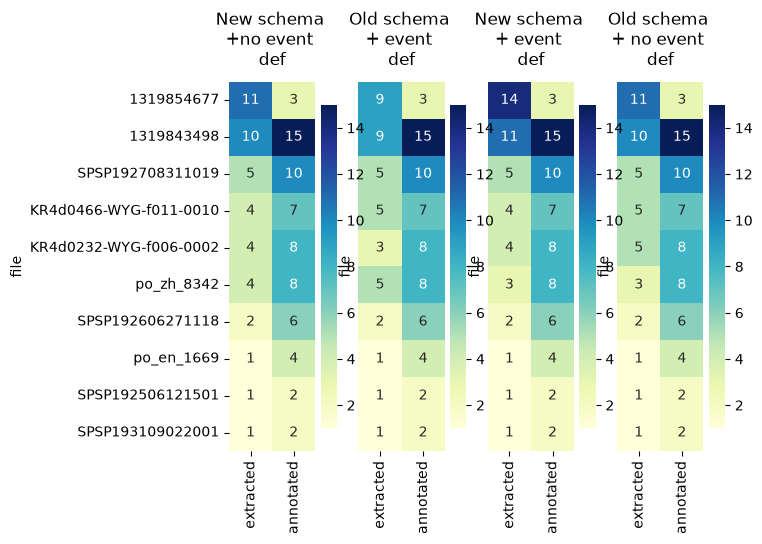

In [334]:
# --- heatmap: extracted vs annotated counts, per file ---
plt.figure(figsize=(6, 6))
fig, (ax,ax2, ax3, ax4) = plt.subplots(ncols=4)

pivot1 = matrix_conf1.set_index("file")[["extracted", "annotated"]]
pivot2 = matrix_conf2.set_index("file")[["extracted", "annotated"]]
pivot3 = matrix_conf3.set_index("file")[["extracted", "annotated"]]
pivot4 = matrix_conf4.set_index("file")[["extracted", "annotated"]]
sns.heatmap(pivot1, annot=True, fmt="d", cmap="YlGnBu", cbar=True, ax=ax)
sns.heatmap(pivot2, annot=True, fmt="d", cmap="YlGnBu", cbar=True, ax=ax2, yticklabels=False)
sns.heatmap(pivot3, annot=True, fmt="d", cmap="YlGnBu", cbar=True, ax=ax3, yticklabels=False)
sns.heatmap(pivot4, annot=True, fmt="d", cmap="YlGnBu", cbar=True, ax=ax4, yticklabels=False)
ax.set_title("New schema \n+no event \ndef", pad=12)
ax2.set_title("Old schema \n+ event \ndef", pad=12)
ax3.set_title("New schema \n+ event \ndef", pad=12)
ax4.set_title("Old schema \n+ no event \ndef", pad=12)
